# Reinforcement Learning Assignment
## Part-I: Implementation of Book Examples

### Question

Implement the Windy Gridworld problem (Example 6.5) using
ε-greedy Sarsa and verify the results.

### Objective

Implement the Windy Gridworld environment using the Sarsa
on-policy reinforcement learning algorithm with an ε-greedy
action-selection policy.

The learned agent should discover an efficient path from the
start state to the goal despite the presence of upward wind.

## 1. Windy Gridworld — Problem Setup

The environment consists of a 7 × 10 grid.

Start state:
S = (3, 0)

Goal state:
G = (3, 7)

The agent can take four actions:

- UP
- DOWN
- LEFT
- RIGHT

The wind strength depends on the column:

Wind = [0, 0, 0, 1, 1, 1, 2, 2, 1, 0]

The wind always pushes the agent upward.

Reward:
- −1 for every normal time step
- 0 when the goal is reached

Parameters:

α = 0.5       Learning rate
γ = 1.0       Discount factor
ε = 0.1       Exploration probability

Initial Q(s,a) = 0 for every state-action pair.

Training is performed for 8000 time steps.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Step 1 — Represent the Grid

The grid has:

- 7 rows
- 10 columns

Python uses zero-based indexing.

Therefore:

Start = (3, 0)
Goal  = (3, 7)

The state is represented as:

(row, column)

For example:

(3, 0) → row 3, column 0
(3, 7) → row 3, column 7

In [ ]:
# Grid dimensions

ROWS = 7
COLS = 10

# Start and goal states

START = (3, 0)
GOAL = (3, 7)

# Wind strength in each column

WIND = [0, 0, 0, 1, 1, 1, 2, 2, 1, 0]

print("Grid:", ROWS, "x", COLS)
print("Start:", START)
print("Goal:", GOAL)
print("Wind:", WIND)

Grid: 7 x 10
Start: (3, 0)
Goal: (3, 7)
Wind: [0, 0, 0, 1, 1, 1, 2, 2, 1, 0]


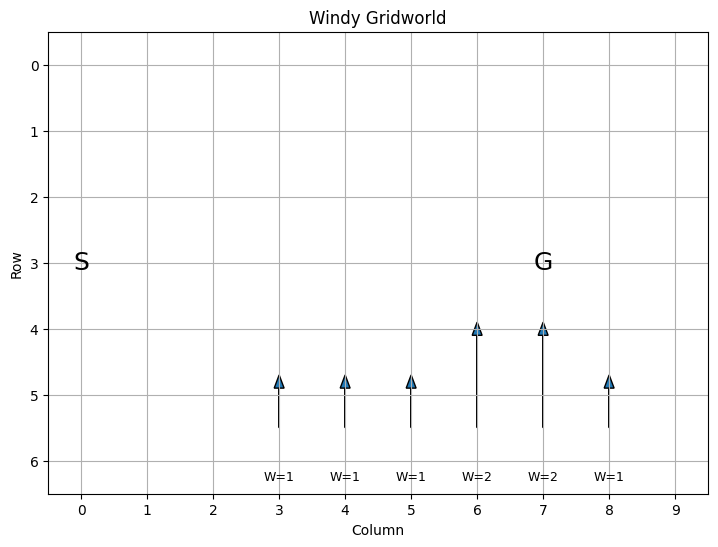

In [ ]:
def draw_grid():

    grid = np.zeros((ROWS, COLS))

    plt.figure(figsize=(10, 6))

    plt.imshow(grid, cmap="Greys", origin="upper")

    # Start
    plt.text(
        START[1],
        START[0],
        "S",
        ha="center",
        va="center",
        fontsize=18
    )

    # Goal
    plt.text(
        GOAL[1],
        GOAL[0],
        "G",
        ha="center",
        va="center",
        fontsize=18
    )

    # Wind arrows
    for col in range(COLS):

        wind = WIND[col]

        if wind > 0:

            plt.arrow(
                col,
                5.5,
                0,
                -wind * 0.8,
                head_width=0.15,
                head_length=0.2,
                length_includes_head=True
            )

            plt.text(
                col,
                6.3,
                f"W={wind}",
                ha="center",
                fontsize=9
            )

    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))

    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.title("Windy Gridworld")

    plt.grid(True)

    plt.show()


draw_grid()

## 3. Step 2 — How does the agent move?

The agent chooses an action, but the environment also applies wind.

Therefore:

Next State = Current State + Action + Wind effect

The wind always pushes upward.

Because rows increase downward in a Python grid:

UP means decreasing the row number.

Therefore, wind is implemented as:

new_row = new_row - WIND[current_column]

Example:

Current state = (3, 3)
Action = RIGHT
Wind = 1

Normal movement:

(3,3) → (3,4)

Wind pushes upward:

row 3 → row 2

Therefore:

(3,3) + RIGHT → (2,4)

In [ ]:
# Action numbers

UP = 0
DOWN = 1
LEFT = 2
RIGHT = 3

# Movement associated with each action

ACTIONS = {
    UP: (-1, 0),
    DOWN: (1, 0),
    LEFT: (0, -1),
    RIGHT: (0, 1)
}

ACTION_NAMES = {
    UP: "UP",
    DOWN: "DOWN",
    LEFT: "LEFT",
    RIGHT: "RIGHT"
}

print(ACTION_NAMES)

{0: 'UP', 1: 'DOWN', 2: 'LEFT', 3: 'RIGHT'}


In [ ]:
def step(state, action):

    row, col = state

    # Movement caused by chosen action
    dr, dc = ACTIONS[action]

    new_row = row + dr
    new_col = col + dc

    # Apply upward wind
    # Wind depends on the current column
    new_row = new_row - WIND[col]

    # Keep the agent inside the grid
    new_row = max(0, min(ROWS - 1, new_row))
    new_col = max(0, min(COLS - 1, new_col))

    next_state = (new_row, new_col)

    # Reward
    if next_state == GOAL:
        reward = 0
    else:
        reward = -1

    return next_state, reward

In [ ]:
state = (3, 3)
action = RIGHT

next_state, reward = step(state, action)

print("Current state :", state)
print("Action        :", ACTION_NAMES[action])
print("Next state    :", next_state)
print("Reward        :", reward)

Current state : (3, 3)
Action        : RIGHT
Next state    : (2, 4)
Reward        : -1


## 4. Step 3 — Initialize the Q-table

Q(s,a) represents the expected return for taking action a
in state s.

There are:

7 × 10 = 70 states

and:

4 actions per state.

Therefore:

70 × 4 = 280 state-action values.

Initially:

Q(s,a) = 0

because the agent has no previous experience.

In [ ]:
# Initialize Q-table

Q = np.zeros((ROWS, COLS, 4))

print("Q-table shape:", Q.shape)
print("Total Q-values:", Q.size)

print("\nInitial Q-values at START:")
print(Q[START[0], START[1], :])

Q-table shape: (7, 10, 4)
Total Q-values: 280

Initial Q-values at START:
[0. 0. 0. 0.]


## 5. Step 4 — ε-Greedy Action Selection

The agent must balance:

Exploration:
Try actions that may provide new information.

Exploitation:
Choose the action with the highest Q-value.

We use:

ε = 0.1

Therefore:

90% probability → exploit
10% probability → explore

If all Q-values are initially equal to zero, the agent
cannot distinguish between actions. Random tie-breaking
allows different actions to be explored.

In [ ]:
def epsilon_greedy(Q, state, epsilon):

    row, col = state

    # Exploration
    if np.random.rand() < epsilon:

        return np.random.randint(4)

    # Exploitation
    q_values = Q[row, col, :]

    max_q = np.max(q_values)

    # Random tie-breaking between equally good actions
    best_actions = np.flatnonzero(q_values == max_q)

    return np.random.choice(best_actions)

## 6. Step 5 — Sarsa Update

Sarsa stands for:

S → Current State
A → Current Action
R → Reward
S' → Next State
A' → Next Action

The update equation is:

Q(S,A) ← Q(S,A)
       + α [R + γQ(S',A') − Q(S,A)]

For this problem:

α = 0.5
γ = 1.0

Therefore:

Q(S,A) ← Q(S,A)
       + 0.5 [R + Q(S',A') − Q(S,A)]

The important point is that Sarsa chooses A' using the
same ε-greedy policy.

## 7. One Sarsa Update by Hand

Suppose:

Current state:
S = (3,3)

Current action:
A = RIGHT

After applying the wind:

S' = (2,4)

Reward:
R = −1

Suppose the next action is:

A' = UP

Assume:

Q(S,A) = −4
Q(S',A') = −5

Parameters:

α = 0.5
γ = 1

Sarsa:

Q(S,A) ← Q(S,A)
       + α[R + γQ(S',A') − Q(S,A)]

Substitution:

Q(S,A) = −4 + 0.5[−1 + (1)(−5) − (−4)]

Q(S,A) = −4 + 0.5[−2]

Q(S,A) = −5

Therefore:

Old Q-value = −4
New Q-value = −5

In [ ]:
def sarsa(alpha=0.5,
          gamma=1.0,
          epsilon=0.1,
          max_steps=8000):

    # Initialize Q-table
    Q = np.zeros((ROWS, COLS, 4))

    # Store episode information
    episode_lengths = []
    cumulative_steps = []

    total_steps = 0

    # Continue training until 8000 time steps
    while total_steps < max_steps:

        # ---------------------------------------------
        # Start a new episode
        # ---------------------------------------------

        state = START

        # Choose first action
        action = epsilon_greedy(
            Q,
            state,
            epsilon
        )

        episode_length = 0

        # ---------------------------------------------
        # Run the episode
        # ---------------------------------------------

        while True:

            # Take action
            next_state, reward = step(
                state,
                action
            )

            # One time step has passed
            total_steps += 1
            episode_length += 1

            # -----------------------------------------
            # Goal reached
            # -----------------------------------------

            if next_state == GOAL:

                # Terminal state has no next action
                current_q = Q[
                    state[0],
                    state[1],
                    action
                ]

                Q[
                    state[0],
                    state[1],
                    action
                ] += alpha * (
                    reward - current_q
                )

                break

            # -----------------------------------------
            # Choose next action
            # -----------------------------------------

            next_action = epsilon_greedy(
                Q,
                next_state,
                epsilon
            )

            # -----------------------------------------
            # Sarsa update
            # -----------------------------------------

            current_q = Q[
                state[0],
                state[1],
                action
            ]

            next_q = Q[
                next_state[0],
                next_state[1],
                next_action
            ]

            target = reward + gamma * next_q

            td_error = target - current_q

            Q[
                state[0],
                state[1],
                action
            ] += alpha * td_error

            # -----------------------------------------
            # Move to next state and action
            # -----------------------------------------

            state = next_state
            action = next_action

            # Stop exactly at maximum training steps
            if total_steps >= max_steps:
                break

        # ---------------------------------------------
        # Save episode results
        # ---------------------------------------------

        episode_lengths.append(episode_length)
        cumulative_steps.append(total_steps)

    return Q, np.array(cumulative_steps), np.array(episode_lengths)

## 8. Step 6 — Train the Sarsa Agent

We now train the agent for:

8000 total time steps.

Parameters:

α = 0.5
γ = 1.0
ε = 0.1

The Q-table is updated after every interaction with
the environment.

In [ ]:
# Run Sarsa

Q, time_steps, episode_lengths = sarsa(
    alpha=0.5,
    gamma=1.0,
    epsilon=0.1,
    max_steps=8000
)

print("Training completed!")
print("Total time steps:", time_steps[-1])
print("Number of episodes:", len(episode_lengths))

Training completed!
Total time steps: 8000
Number of episodes: 177


## 9. Episode Length

Episode length is the number of actions taken from the
start state until the goal is reached.

Example:

S → → → ↓ → ↑ → G

If 7 actions were taken:

Episode length = 7

Why is this important?

Every non-terminal step gives a reward of −1.

Therefore:

5 steps → return approximately −5
10 steps → return approximately −10

Hence, a shorter episode is better.

The agent learns to reduce the number of steps required
to reach the goal.

In [ ]:
print("First 10 episode lengths:")
print(episode_lengths[:10])

print("\nLast 10 episode lengths:")
print(episode_lengths[-10:])

print("\nAverage episode length:",
      np.mean(episode_lengths))

print("Average last 100 episodes:",
      np.mean(episode_lengths[-100:]))

First 10 episode lengths:
[912 278 133 194  51 250  30  46  41  66]

Last 10 episode lengths:
[22 18 21 18 16 20 18 18 19  2]

Average episode length: 45.19774011299435
Average last 100 episodes: 27.68


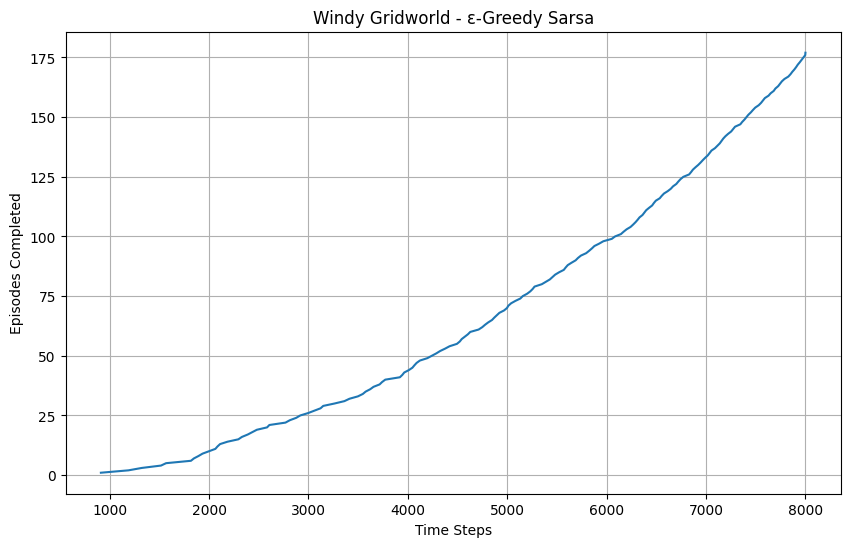

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    time_steps,
    np.arange(1, len(episode_lengths) + 1)
)

plt.xlabel("Time Steps")
plt.ylabel("Episodes Completed")
plt.title("Windy Gridworld - ε-Greedy Sarsa")

plt.grid(True)

plt.show()

## 10. Step 8 — Extract the Learned Greedy Policy

After training, Q contains the learned action values.

For every state:

π(s) = argmax Q(s,a)

The greedy policy selects the action with the highest Q-value.

We use the greedy policy without exploration to examine
what the agent has learned.

In [ ]:
def get_greedy_path(Q):

    state = START
    path = [state]

    for _ in range(100):

        row, col = state

        # Select best learned action
        action = np.argmax(Q[row, col, :])

        # Apply action and wind
        next_state, reward = step(
            state,
            action
        )

        path.append(next_state)

        # Stop at goal
        if next_state == GOAL:
            break

        state = next_state

    return path


path = get_greedy_path(Q)

print("Learned greedy path:\n")

for i, state in enumerate(path):

    print(
        f"Step {i:2d}: {state}"
    )

print("\nGreedy path length:",
      len(path) - 1)

Learned greedy path:

Step  0: (3, 0)
Step  1: (2, 0)
Step  2: (2, 1)
Step  3: (1, 1)
Step  4: (1, 2)
Step  5: (2, 2)
Step  6: (2, 3)
Step  7: (1, 4)
Step  8: (0, 5)
Step  9: (0, 6)
Step 10: (0, 7)
Step 11: (0, 8)
Step 12: (0, 9)
Step 13: (1, 9)
Step 14: (2, 9)
Step 15: (3, 9)
Step 16: (4, 9)
Step 17: (4, 8)
Step 18: (3, 7)

Greedy path length: 18


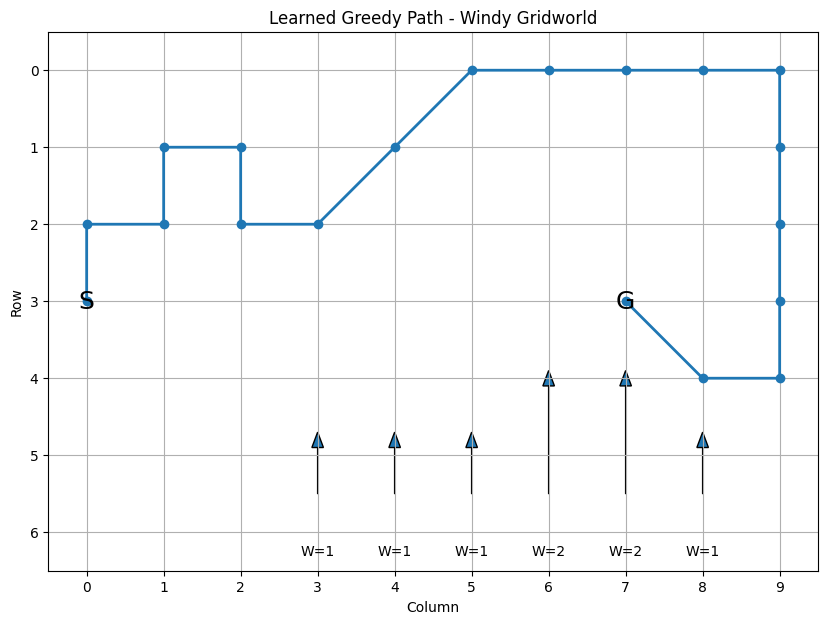

In [ ]:
def plot_learned_path(Q):

    path = get_greedy_path(Q)

    plt.figure(figsize=(12, 7))

    grid = np.zeros((ROWS, COLS))

    plt.imshow(
        grid,
        cmap="Greys",
        origin="upper"
    )

    # Plot path
    rows = [p[0] for p in path]
    cols = [p[1] for p in path]

    plt.plot(
        cols,
        rows,
        marker="o",
        linewidth=2
    )

    # Start
    plt.text(
        START[1],
        START[0],
        "S",
        ha="center",
        va="center",
        fontsize=18
    )

    # Goal
    plt.text(
        GOAL[1],
        GOAL[0],
        "G",
        ha="center",
        va="center",
        fontsize=18
    )

    # Wind
    for col in range(COLS):

        wind = WIND[col]

        if wind > 0:

            plt.arrow(
                col,
                5.5,
                0,
                -wind * 0.8,
                head_width=0.15,
                head_length=0.2,
                length_includes_head=True
            )

            plt.text(
                col,
                6.3,
                f"W={wind}",
                ha="center"
            )

    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))

    plt.xlabel("Column")
    plt.ylabel("Row")

    plt.title(
        "Learned Greedy Path - Windy Gridworld"
    )

    plt.grid(True)

    plt.show()


plot_learned_path(Q)

## 11. Verification of Results

The implementation is verified using three observations:

### 1. Learning occurs

The Q-values change from their initial value of zero
after the agent interacts with the environment.

### 2. Episodes become more efficient

The agent gradually learns how to compensate for the
upward wind.

### 3. A learned path reaches the goal

The greedy policy obtained from the final Q-table should
produce an efficient path from:

S = (3,0)

to:

G = (3,7)

The exact path can vary because ε-greedy Sarsa involves
random exploration.

The optimal greedy solution for the standard Windy
Gridworld is approximately 15 steps.

In [ ]:
print("=" * 60)
print("FINAL Q-VALUES AT IMPORTANT STATES")
print("=" * 60)

states_to_check = [
    (3, 0),
    (3, 1),
    (3, 2),
    (3, 3),
    (2, 4),
    (1, 5),
    (0, 6)
]

for state in states_to_check:

    q_values = Q[
        state[0],
        state[1],
        :
    ]

    best_action = np.argmax(q_values)

    print(
        f"\nState {state}"
    )

    for action in range(4):

        print(
            f"  {ACTION_NAMES[action]:5s} : "
            f"{q_values[action]:8.3f}"
        )

    print(
        "  Best action:",
        ACTION_NAMES[best_action]
    )

FINAL Q-VALUES AT IMPORTANT STATES

State (3, 0)
  UP    :  -16.392
  DOWN  :  -16.410
  LEFT  :  -16.509
  RIGHT :  -16.402
  Best action: UP

State (3, 1)
  UP    :  -15.583
  DOWN  :  -15.491
  LEFT  :  -16.134
  RIGHT :  -15.542
  Best action: DOWN

State (3, 2)
  UP    :  -14.751
  DOWN  :  -14.752
  LEFT  :  -15.195
  RIGHT :  -14.675
  Best action: RIGHT

State (3, 3)
  UP    :  -13.614
  DOWN  :  -13.923
  LEFT  :  -14.344
  RIGHT :  -13.803
  Best action: UP

State (2, 4)
  UP    :  -13.164
  DOWN  :  -12.775
  LEFT  :  -13.662
  RIGHT :  -12.783
  Best action: DOWN

State (1, 5)
  UP    :  -11.565
  DOWN  :  -11.525
  LEFT  :  -12.799
  RIGHT :  -10.345
  Best action: RIGHT

State (0, 6)
  UP    :  -10.691
  DOWN  :  -10.990
  LEFT  :  -11.969
  RIGHT :   -9.892
  Best action: RIGHT


## 12. Why Doesn't the Agent Simply Move RIGHT?

Without wind:

S → → → → → → → G

would take only 7 steps.

However, Windy Gridworld has upward wind.

For example:

At (3,3):

Action = RIGHT

Normal movement:

(3,3) → (3,4)

Wind = 1

Therefore:

(3,4) → (2,4)

The agent cannot directly control the final position.
It only chooses an action.

The environment determines the actual next state using:

Action + Wind.

Therefore, the optimal policy may temporarily move
away from the goal or use DOWN to compensate for the
upward wind.

This is why the learned path may look curved,
indirect, or like a half-circle.

## 13. Why γ = 1?

γ is the discount factor.

In Windy Gridworld, the objective is to reach the goal
using as few steps as possible.

Every step gives:

R = −1

Therefore:

5 steps  → total reward ≈ −5
10 steps → total reward ≈ −10
15 steps → total reward ≈ −15

A shorter route has a higher return.

Using:

γ = 1

means future rewards are not discounted.

Therefore, all future step penalties contribute equally.

This makes the problem naturally represent:

"Find the shortest route to the goal under the wind dynamics."

In [ ]:
import numpy as np

# -----------------------------
# Simple Windy Gridworld
# -----------------------------

ROWS = 7
COLS = 10

START = (3, 0)
GOAL = (3, 7)

WIND = [0, 0, 0, 1, 1, 1, 2, 2, 1, 0]

UP = 0
DOWN = 1
LEFT = 2
RIGHT = 3

ACTIONS = {
    UP: (-1, 0),
    DOWN: (1, 0),
    LEFT: (0, -1),
    RIGHT: (0, 1)
}

ACTION_NAMES = ["UP", "DOWN", "LEFT", "RIGHT"]


# Environment
def step(state, action):

    row, col = state

    dr, dc = ACTIONS[action]

    row = row + dr
    col = col + dc

    # Apply wind
    row = row - WIND[max(0, min(COLS - 1, col))]

    # Boundary
    row = max(0, min(ROWS - 1, row))
    col = max(0, min(COLS - 1, col))

    next_state = (row, col)

    if next_state == GOAL:
        reward = 0
    else:
        reward = -1

    return next_state, reward


# Q-table
Q = np.zeros((ROWS, COLS, 4))

alpha = 0.5
gamma = 1.0
epsilon = 0.1

total_steps = 0
max_steps = 8000

episode_lengths = []


# Training
while total_steps < max_steps:

    state = START
    episode_length = 0

    # ε-greedy first action
    if np.random.rand() < epsilon:
        action = np.random.randint(4)
    else:
        action = np.argmax(Q[state[0], state[1], :])

    while state != GOAL:

        # Take action
        next_state, reward = step(state, action)

        total_steps += 1
        episode_length += 1

        # Choose next action
        if next_state == GOAL:

            # Terminal update
            Q[state[0], state[1], action] += alpha * (
                reward - Q[state[0], state[1], action]
            )

            break

        if np.random.rand() < epsilon:
            next_action = np.random.randint(4)
        else:
            next_action = np.argmax(
                Q[next_state[0], next_state[1], :]
            )

        # Sarsa update
        Q[state[0], state[1], action] += alpha * (
            reward
            + gamma * Q[
                next_state[0],
                next_state[1],
                next_action
            ]
            - Q[
                state[0],
                state[1],
                action
            ]
        )

        # Move forward
        state = next_state
        action = next_action

    episode_lengths.append(episode_length)


print("Training completed")
print("Total steps:", total_steps)
print("Episodes:", len(episode_lengths))
print("Average last 100 episode length:",
      np.mean(episode_lengths[-100:]))

Training completed
Total steps: 8007
Episodes: 147
Average last 100 episode length: 27.32




```
# This is formatted as code
```

# 14. Explanation

The Windy Gridworld demonstrates on-policy reinforcement
learning using ε-greedy Sarsa.

The agent begins with:

Q(s,a) = 0

and has no knowledge of the environment.

During each episode:

1. Start from (3,0)
2. Select an action using ε-greedy
3. Apply the action
4. Apply the wind
5. Receive reward −1
6. Observe the next state
7. Select the next action
8. Update Q using Sarsa
9. Continue until (3,7) is reached

The learned Q-values influence future action selection.

After many episodes, the agent learns an efficient route
that compensates for the upward wind.

The experiment therefore demonstrates:

Experience → Q-value update → Better action selection
→ Shorter episodes → Efficient path to goal.

In [ ]:
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROWS, COLS = 4, 12
START, GOAL = (3, 0), (3, 11)
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # up, down, left, right
ARROWS = ["^", "v", "<", ">"]
ALPHA, GAMMA, EPS = 0.5, 1.0, 0.1


def step(state, a):
    """Environment dynamics. Reward -1 per step, -100 for cliff (back to start)."""
    r, c = state
    dr, dc = ACTIONS[a]
    r = min(max(r + dr, 0), ROWS - 1)
    c = min(max(c + dc, 0), COLS - 1)
    if r == 3 and 1 <= c <= 10:          # the cliff
        return START, -100, False
    if (r, c) == GOAL:
        return (r, c), -1, True
    return (r, c), -1, False


def eps_greedy(Q, s, rng, eps=EPS):
    if rng.random() < eps:
        return int(rng.integers(4))
    q = Q[s]
    return int(rng.choice(np.flatnonzero(q == q.max())))  # random tie-break


def run(method, episodes=500, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((ROWS, COLS, 4))
    rewards = np.zeros(episodes)
    for ep in range(episodes):
        s = START
        a = eps_greedy(Q, s, rng)
        done = False
        while not done:
            s2, r, done = step(s, a)
            a2 = eps_greedy(Q, s2, rng)
            if method == "sarsa":
                target = r + GAMMA * Q[s2][a2] * (not done)
            else:  # q-learning
                target = r + GAMMA * Q[s2].max() * (not done)
            Q[s][a] += ALPHA * (target - Q[s][a])
            s, a = s2, a2
            rewards[ep] += r
    return Q, rewards


def greedy_path(Q):
    grid = [["." for _ in range(COLS)] for _ in range(ROWS)]
    for c in range(1, 11):
        grid[3][c] = "C"
    s, seen = START, set()
    while s != GOAL and s not in seen:
        seen.add(s)
        a = int(np.argmax(Q[s]))
        grid[s[0]][s[1]] = ARROWS[a]
        s, _, _ = step(s, a)
    grid[3][0], grid[3][11] = "S" if grid[3][0] == "." else grid[3][0], "G"
    return "\n".join(" ".join(row) for row in grid)


if __name__ == "__main__":
    EPISODES, RUNS = 500, 500
    avg = {"sarsa": np.zeros(EPISODES), "qlearning": np.zeros(EPISODES)}
    for m in avg:
        for k in range(RUNS):
            Q, R = run(m, EPISODES, seed=k)
            avg[m] += R / RUNS
        print(f"{m}: mean reward over last 100 episodes = {avg[m][-100:].mean():.1f}")

    # Figure: online performance (like the book graph)
    def smooth(x, w=10):
        return np.convolve(x, np.ones(w) / w, mode="valid")

    plt.figure(figsize=(7, 4.5))
    plt.plot(smooth(avg["sarsa"]), label="Sarsa", color="tab:blue")
    plt.plot(smooth(avg["qlearning"]), label="Q-learning", color="tab:red")
    plt.ylim(-100, -20)
    plt.xlabel("Episodes")
    plt.ylabel("Sum of rewards during episode")
    plt.title(f"Cliff Walking (eps={EPS}, alpha={ALPHA}, avg of {RUNS} runs)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    # Fix for FileNotFoundError: ensure directory exists
    output_path = "/mnt/user-data/outputs/cliff_walking_result.png"
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    plt.savefig(output_path, dpi=150)

    # Learned greedy paths from a single long run
    Qs, _ = run("sarsa", 500, seed=1)
    Qq, _ = run("qlearning", 500, seed=1)
    print("\nSarsa greedy path (safe, upper route):\n" + greedy_path(Qs))
    print("\nQ-learning greedy path (optimal, cliff edge):\n" + greedy_path(Qq))

sarsa: mean reward over last 100 episodes = -26.9
qlearning: mean reward over last 100 episodes = -49.7

Sarsa greedy path (safe, upper route):
. . . . . . . > > > > v
> > > > > > > ^ . . . v
^ . . . . . . . . . . v
^ C C C C C C C C C C G

Q-learning greedy path (optimal, cliff edge):
. . . . . . . . . . . .
. . . . . . . . . . . .
> > > > > > > > > > > v
^ C C C C C C C C C C G
